# A 1D diffusion model

This is a 1D diffusion model
It assumes a constant diffusivity
It used regular grid
It has a step funciton for initial profile
It has fixed boundary conditions.

The diffusion equation

$$ \frac{\partial z}{\partial t} = D\frac{\partial^2 z}{\partial x^2} $$


Where $z$ is elevation, $t$ is time, $x$ is the spatial dimention, $D$ is the transport rate coefficient, clled hillslope diffusivity---- with dimensions length squared pet time.

The discretized version of the diffusion equation we will use in our model:

$$ z^{t+1}_x = z^t_x + {D \Delta t \over \Delta x^2} (z^t_{x+1} - 2z^t_x + z^t_{x-1}) $$

This is forward in time center in space schele (look up details in textbook)

We'll use two libraries, NumPy (for arrays) and Matplotlib (for plots), that arn't a part of the core python distribution.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Start by setting the fixed model parameters --- the diffusivity and the size of the model domain.

In [2]:
D = 100 # diffusivity
Lx = 300 # model domain

Next, set up the grid using NumPy array

In [3]:
dx = 0.5 # grid spacing
x = np.arange(start = 0, stop = Lx, step = dx)
nx = len(x) # number of grid nodes

Set initial conditions for the model.
The elevation $z$ is a step function with a heigh value to the left, a low value on the right, and a cliff in the middle of the domain.

In [8]:
z = np.zeros_like(x) #array of 0 of type np (float)
z_left = 500 # left side is at 500 (elevation)
z_right = 0 # right side is at 0
z[x <= Lx / 2] = z_left # cliff z for values x that are <= half domain size set to z_left
z[x >= Lx / 2] = z_right # cliff z for values x that are >= half domain size set to z_right

Plot initial profile

Text(0.5, 1.0, 'initial hillslope profile')

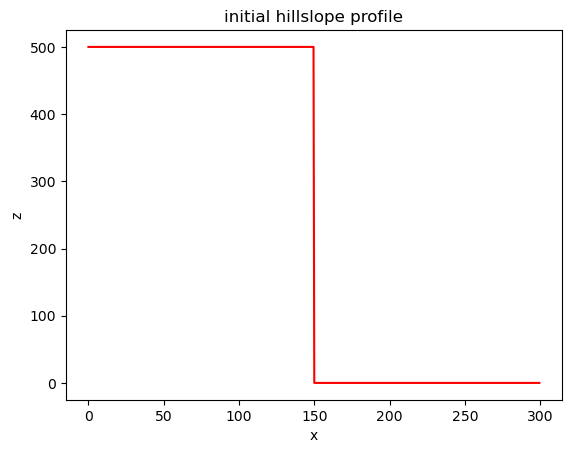

In [10]:
plt.figure()
plt.plot(x,z,"r")
plt.xlabel("x")
plt.ylabel("z")
plt.title("initial hillslope profile")

Set up time stepping for the model.
Calculate a stable time from a stablity criterion.

In [11]:
nt = 5000 # number of time steps
dt = 0.5 * dx ** 2 / D # time step double star is exponental 

Loop over the time steps of the model, solving the diffusion equation using the FTCS scheme described above.
Note the use of array operations on the elevation $z$.
The boundary conditions remain fixed in each time step

In [14]:
for t in range(0, nt):
	z[1:-1] += D * dt / dx ** 2 * (z[:-2] - 2*z[1:-1] + z[2:])


plot the results.

Text(0.5, 1.0, 'Final hillslope profile')

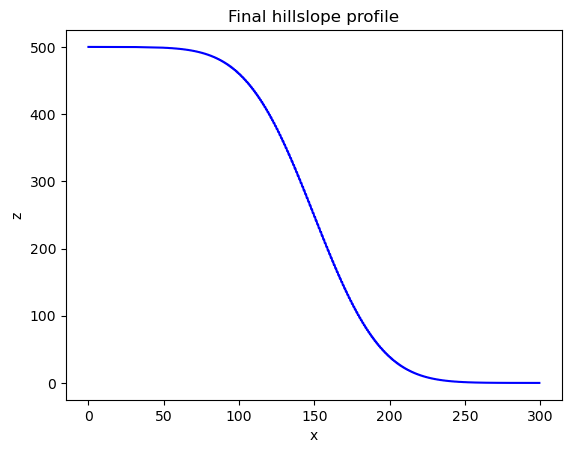

In [15]:
plt.figure()
plt.plot(x,z,"b")
plt.xlabel("x")
plt.ylabel("z")
plt.title("Final hillslope profile")